# Exercise 3 – Naive Bayes classifier on Iris

Source: *Supervised Learning Exercise.pdf*, Exercise 3.

**Task:** Implement a Naive Bayes classifier on the Iris dataset from Exercise 2. Discretise every column into three categories (low / medium / high), repeat the evaluation (30 random 70/30 splits, one confusion matrix), and compare the result with k-NN.

**Data:** `iris.csv` (must be in the same folder as this notebook).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

np.random.seed(0)   # fixed seed -> reproducible results

# Iris data: 150 flowers, 4 features, 3 species.
# iris.csv must be in the same folder as this notebook.
data = np.loadtxt("iris.csv", delimiter=",", skiprows=1)
X_iris, y_iris = data[:, :4], data[:, 4].astype(int)
print("Shape:", X_iris.shape, " Class counts:", np.bincount(y_iris).tolist())

Shape: (150, 4)  Class counts: [50, 50, 50]


## Step 0 – k-NN results for the comparison

Exercise 3, item 2 asks how Naive Bayes compares with k-NN. We therefore compute the k-NN accuracies here with the same 30-split procedure as in Exercise 2. The helper functions are defined in this notebook as well.

In [2]:
def split_70_30(X, y):
    """Random 70 % training / 30 % test split."""
    p = np.random.permutation(len(X))
    n = int(0.7 * len(X))
    return X[p[:n]], y[p[:n]], X[p[n:]], y[p[n:]]

def knn_predict(X_train, y_train, x, k):
    dist = np.sqrt(np.sum((X_train - x) ** 2, axis=1))   # Euclidean distance to all training examples
    nearest = np.argsort(dist)[:k]                       # indices of the k closest examples
    votes = Counter(y_train[nearest])
    return votes.most_common(1)[0][0]                    # majority class

def knn_accuracy(X_train, y_train, X_test, y_test, k):
    preds = np.array([knn_predict(X_train, y_train, x, k) for x in X_test])
    return np.mean(preds == y_test), preds

def multiclass_confusion(y_true, y_pred, n_classes=3):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1                                    # rows = true class, columns = predicted class
    return cm

def macro_metrics(cm):
    """Precision, recall and F1 per class, then averaged over the classes."""
    precs, recs, f1s = [], [], []
    for c in range(cm.shape[0]):
        TP = cm[c, c]; FP = cm[:, c].sum() - TP; FN = cm[c, :].sum() - TP
        p = TP / (TP + FP) if TP + FP > 0 else 0.0
        r = TP / (TP + FN) if TP + FN > 0 else 0.0
        f = 2 * p * r / (p + r) if p + r > 0 else 0.0
        precs.append(p); recs.append(r); f1s.append(f)
    acc = np.trace(cm) / cm.sum()
    return acc, np.mean(precs), np.mean(recs), np.mean(f1s)

In [3]:
ks = [3, 7, 11]
acc_knn = {k: [] for k in ks}
for run in range(30):
    Xtr, ytr, Xte, yte = split_70_30(X_iris, y_iris)
    for k in ks:
        a_, _ = knn_accuracy(Xtr, ytr, Xte, yte, k)
        acc_knn[k].append(a_)
for k in ks:
    print(f"k-NN, k = {k:2d}: mean accuracy = {np.mean(acc_knn[k]):.3f}")

k-NN, k =  3: mean accuracy = 0.962
k-NN, k =  7: mean accuracy = 0.964
k-NN, k = 11: mean accuracy = 0.964


## Step 1 – Discretise the features

Naive Bayes works best with categories. Each feature is split into three groups: **low (0)**, **medium (1)** and **high (2)**. The cut-offs are the **tertiles** (the 33 % and 67 % points) of each column, so each group contains about a third of the flowers.

**Note:** The cut-offs are computed from the full dataset. They use only the features and no labels, but in a strict setup they should be computed on the training data only.

In [4]:
# Discretise each column into 0 = low, 1 = medium, 2 = high using the tertiles
cuts = np.quantile(X_iris, [1/3, 2/3], axis=0)          # shape (2, 4)
def discretise(X):
    Xd = np.zeros(X.shape, dtype=int)
    for j in range(X.shape[1]):
        Xd[:, j] = np.digitize(X[:, j], cuts[:, j])     # 0, 1 or 2
    return Xd

X_cat = discretise(X_iris)
print("First five rows (categorical):")
print(X_cat[:5])

First five rows (categorical):
[[0 2 0 0]
 [0 1 0 0]
 [0 2 0 0]
 [0 1 0 0]
 [0 2 0 0]]


## Step 2 – Train and predict Naive Bayes

**Training:** For each class we estimate
- the prior $$P(\text{class})$$ = share of the class in the training data,
- the likelihood $$P(x_j \mid \text{class})$$ = counts of each category per feature and class.

**Laplace smoothing:** every count starts at 1, so a category that never occurred in training does not get probability 0.

**Prediction:** choose the class $$c$$ with the largest $$\log P(c) + \sum_j \log P(x_j \mid c)$$. Logarithms turn the product into a sum and keep the numbers stable.

In [5]:
def nb_train(X, y, n_classes=3, n_values=3):
    prior = np.zeros(n_classes)
    likelihood = np.ones((n_classes, X.shape[1], n_values))      # Laplace: start counts at 1
    for c in range(n_classes):
        Xc = X[y == c]
        prior[c] = len(Xc) / len(X)
        for j in range(X.shape[1]):
            counts = np.bincount(Xc[:, j], minlength=n_values)
            likelihood[c, j] += counts
        likelihood[c] /= likelihood[c].sum(axis=1, keepdims=True)  # normalise per feature
    return prior, likelihood

def nb_predict(model, x):
    prior, likelihood = model
    scores = []
    for c in range(len(prior)):
        s = np.log(prior[c])
        for j in range(len(x)):
            s += np.log(likelihood[c, j, x[j]])
        scores.append(s)
    return int(np.argmax(scores))

## Step 3 – 30 random splits and metrics (item 1)

Same procedure as in Exercise 2: 30 random 70/30 splits, accuracy for each test, and a summary.

In [6]:
nb_acc = []
for run in range(30):
    p = np.random.permutation(len(X_cat))
    n = int(0.7 * len(X_cat))
    model = nb_train(X_cat[p[:n]], y_iris[p[:n]])
    preds = np.array([nb_predict(model, x) for x in X_cat[p[n:]]])
    nb_acc.append(np.mean(preds == y_iris[p[n:]]))
nb_acc = np.array(nb_acc)
print(f"Naive Bayes: mean accuracy = {nb_acc.mean():.3f}, std = {nb_acc.std():.3f}")

Naive Bayes: mean accuracy = 0.933, std = 0.030


## Step 4 – Confusion matrix and metrics for one test (item 1)

In [7]:
p = np.random.permutation(len(X_cat)); n = int(0.7 * len(X_cat))
model = nb_train(X_cat[p[:n]], y_iris[p[:n]])
preds = np.array([nb_predict(model, x) for x in X_cat[p[n:]]])
cm_nb = multiclass_confusion(y_iris[p[n:]], preds)
print("Confusion matrix (Naive Bayes, one test): rows = true, columns = predicted")
print(cm_nb)
acc, pr, rc, f1 = macro_metrics(cm_nb)
print(f"accuracy = {acc:.3f}, macro precision = {pr:.3f}, macro recall = {rc:.3f}, macro F1 = {f1:.3f}")

Confusion matrix (Naive Bayes, one test): rows = true, columns = predicted
[[15  0  0]
 [ 0 12  2]
 [ 0  1 15]]
accuracy = 0.933, macro precision = 0.935, macro recall = 0.932, macro F1 = 0.933


## Step 5 – Comparison with k-NN (item 2)

The boxplot compares the accuracies of k-NN (k = 3, 7, 11) and Naive Bayes, each over 30 splits.

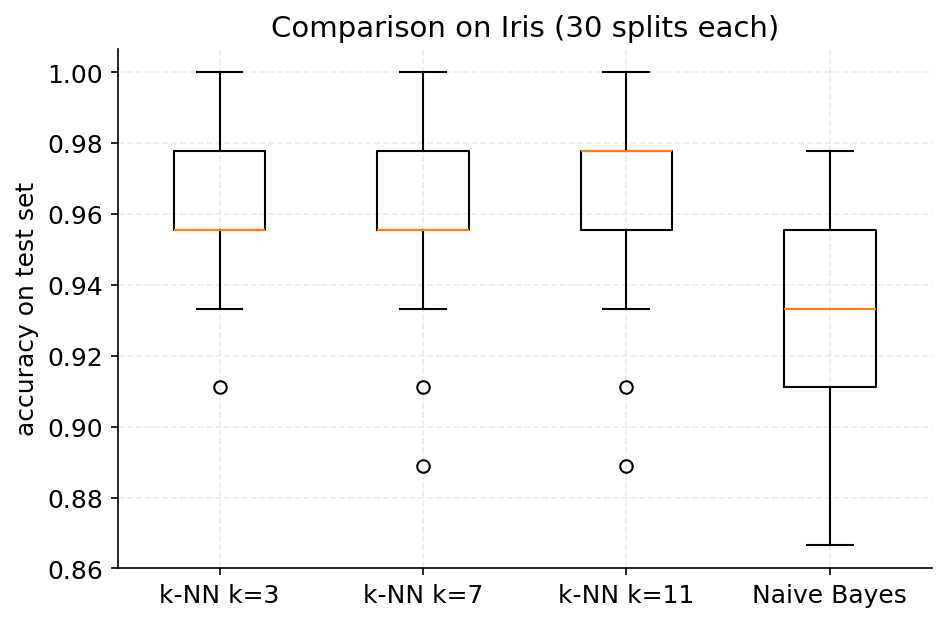

In [8]:
# Compare k-NN (k = 3, 7, 11) with Naive Bayes in one boxplot
plt.figure(figsize=(7, 4.5))
plt.boxplot([acc_knn[3], acc_knn[7], acc_knn[11], nb_acc])
plt.xticks([1, 2, 3, 4], ["k-NN k=3", "k-NN k=7", "k-NN k=11", "Naive Bayes"])
plt.ylabel("accuracy on test set"); plt.title("Comparison on Iris (30 splits each)")
plt.grid(alpha=0.3); plt.show()

## Discussion (item 2)

- In our runs Naive Bayes is **somewhat less accurate** than k-NN (about 0.93 compared with about 0.97).
- **Reason 1:** Discretisation throws away information, because real measurements become three coarse levels.
- **Reason 2:** Naive Bayes assumes that the features are independent. In Iris, sepal and petal measurements are correlated, so this assumption is violated.
- k-NN needs no probabilistic model and compares directly with the data, which suits this dataset better.
- Naive Bayes is very fast and works well with few data and many categories, so it can still be the better choice in other settings.